In [1]:
EXPERIMENT = {
    "start": "2025-02-01",
    "end":   "2025-09-30",
    "interval": "5m",
    "universe_rule": "full_coverage_only",
}


In [2]:
# Import the class from the Python file (module)
import pandas as pd
import matplotlib.pyplot as plt
import os
# from dotenv import load_dotenv
# from pathlib import Path
from sklearn.preprocessing import StandardScaler
import seaborn as sns
from BinanceClient import BinanceClient
import numpy as np
from typing import Final
import joblib
from BatchFeatures import BatchFeatures
from datetime import datetime, timedelta
import helper_functions as hf
import importlib
%matplotlib widget

## Load pair df & Truncate data to 40 Weeks

In [3]:
START_TS = EXPERIMENT["start"]
END_TS   = EXPERIMENT["end"]   # align to 5m bar end

paths = {}
dfs = {}
interval = "5m"

pairs = hf.list_downloaded_pairs("db")

for sym in pairs:
    db_path, df = hf.load_or_fetch_pair_df(sym, interval, weeks=52)

    df = hf.filter_date_range(
        df,
        START_TS,
        END_TS,
        require_full_coverage=True,
        min_coverage_ratio=1.0,      # strict: must cover entire window
        return_none_if_short=True
    )

    if df is None:
        continue

    paths[sym] = db_path
    dfs[sym] = df

print("kept syms:", len(dfs), "out of", len(pairs))

[0GUSDT] DB: ./db/0GUSDT_5m_52weeks.db
[0GUSDT] Loaded 36,249 rows from DB.
[1INCHUSDT] DB: ./db/1INCHUSDT_5m_52weeks.db
[1INCHUSDT] Loaded 104,832 rows from DB.
[2ZUSDT] DB: ./db/2ZUSDT_5m_52weeks.db
[2ZUSDT] Loaded 33,383 rows from DB.
[AAVEUSDT] DB: ./db/AAVEUSDT_5m_52weeks.db
[AAVEUSDT] Loaded 104,832 rows from DB.
[ADAUSDT] DB: ./db/ADAUSDT_5m_52weeks.db
[ADAUSDT] Loaded 104,832 rows from DB.
[AGLDUSDT] DB: ./db/AGLDUSDT_5m_52weeks.db
[AGLDUSDT] Loaded 104,832 rows from DB.
[ALGOUSDT] DB: ./db/ALGOUSDT_5m_52weeks.db
[ALGOUSDT] Loaded 104,832 rows from DB.
[ALLOUSDT] DB: ./db/ALLOUSDT_5m_52weeks.db
[ALLOUSDT] Loaded 21,807 rows from DB.
[APTUSDT] DB: ./db/APTUSDT_5m_52weeks.db
[APTUSDT] Loaded 104,832 rows from DB.
[ARBUSDT] DB: ./db/ARBUSDT_5m_52weeks.db
[ARBUSDT] Loaded 104,832 rows from DB.
[ASTERUSDT] DB: ./db/ASTERUSDT_5m_52weeks.db
[ASTERUSDT] Loaded 32,185 rows from DB.
[ASTRUSDT] DB: ./db/ASTRUSDT_5m_52weeks.db
[ASTRUSDT] Loaded 104,832 rows from DB.
[AUCTIONUSDT] DB: ./db/

## Load COINS, then align timestamps

In [4]:
from tqdm.auto import tqdm
events = []

# for sym, df_feat in tqdm(instability_cache.items(), desc="Cond prob (fast)"):
for sym, df in tqdm(dfs.items()):
    ev = hf.detect_volume_shocks(df)      # ✅ no sym passed
    if not ev.empty:
        ev["symbol"] = sym
        events.append(ev)

events = pd.concat(events, ignore_index=True) if events else pd.DataFrame()


  0%|          | 0/83 [00:00<?, ?it/s]

## Detect Comporession state

In [5]:
# Build dataset
ds = hf.build_preshock_dataset(
    dfs=dfs,
    events=events,
    pre_bars=36,
    gap_bars=2,
    control_per_event=1,
    control_lookahead_bars=36,
    seed=42
)

ds.shape, ds["label"].value_counts()

((10824, 12),
 label
 1    5412
 0    5412
 Name: count, dtype: int64)

In [6]:
df_feat = hf.compute_instability_features_over_window(dfs[sym])
df_feat["is_instability"] = hf.classify_instability(df_feat)

# df_feat["is_instability"].mean(), df_feat["is_instability"].tail(50)


In [10]:
features = ["rvol_mean","rvol_slope","atr_mean_ratio","wick_to_body_ratio","range_pct"]
best_list = [hf.best_threshold_youden(ds, f, higher_is_more_shock=True) for f in features]
pd.DataFrame(best_list).sort_values("J", ascending=False)


,feature,thr,TPR,FPR,J
4,range_pct,0.033882,0.834442,0.265521,0.568921
1,rvol_slope,0.031305,0.586844,0.213230,0.373614
0,rvol_mean,1.666492,0.682557,0.377494,0.305063
2,atr_mean_ratio,1.138417,0.529933,0.270140,0.259793
3,wick_to_body_ratio,1.488581,0.649483,0.470436,0.179047


In [11]:

df_feat = hf.compute_instability_features_over_window(dfs[sym])
df_feat["is_instability"] = hf.classify_pre_shock_instability_v1(df_feat)

ev = events.query("symbol == @sym")
df_feat = hf.mark_future_shock(df_feat, ev, horizon_bars=24)  # 120 min

p_base = df_feat["future_shock"].mean()
p_cond = df_feat.loc[df_feat["is_instability"], "future_shock"].mean()

p_base, p_cond, p_cond / p_base


(np.float64(0.02927574233888977),
 np.float64(0.11863408890197233),
 np.float64(4.052299939270176))

In [12]:
events_by_sym = {s: g["event_ts"].values for s, g in events.groupby("symbol")}

In [13]:
from tqdm.auto import tqdm
import time

# ============================================================
# FIX #1: Cache instability once per symbol (WITH PROGRESS)
# ============================================================
instability_cache = {}

t0 = time.time()

for sym in tqdm(pairs, desc="Computing instability per symbol"):
    if sym not in dfs:
        continue

    df = dfs[sym]
    if df is None or df.empty:
        continue
    
    df_feat = hf.compute_instability_features_over_window(df)
    is_inst = hf.classify_pre_shock_instability_v1(df_feat)
    instability_cache[sym] = pd.DataFrame({"is_instability": is_inst}, index=df_feat.index)

t1 = time.time()
print(f"Instability cache built in {(t1 - t0)/60:.2f} minutes")


Computing instability per symbol:   0%|          | 0/119 [00:00<?, ?it/s]

Instability cache built in 5.57 minutes


In [14]:
# Choose how many cores to use
N_WORKERS = 8  # you said 10–12 is fine
instability_cache = hf.build_instability_cache_parallel(dfs, pairs, n_workers=N_WORKERS)


Instability x8:   0%|          | 0/83 [00:00<?, ?it/s]

Instability cache built for 83/83 symbols in 1.06 min


In [15]:
rows = []
horizon_bars = 24  # 120 min

for sym, df_feat in tqdm(instability_cache.items(), desc="Cond prob (fast)"):
    ev_ts = events_by_sym.get(sym)
    if ev_ts is None or len(ev_ts) == 0:
        continue

    idx = df_feat.index
    is_inst = df_feat["is_instability"].to_numpy(dtype=bool)
    n_inst = int(is_inst.sum())
    if n_inst < 10:
        continue

    fut = hf.future_shock_flag(idx, ev_ts, horizon_bars=horizon_bars)

    p_base = float(fut.mean())
    p_cond = float(fut[is_inst].mean())

    rows.append({
        "symbol": sym,
        "base_prob": p_base,
        "cond_prob": p_cond,
        "lift": (p_cond / p_base) if p_base > 0 else np.nan,
        "instability_rate": float(is_inst.mean()),
        "n_instability": n_inst,
        "n_shocks": int(len(ev_ts)),
    })

prob_df = pd.DataFrame(rows).sort_values("lift", ascending=False)
prob_df.head(20)

Cond prob (fast):   0%|          | 0/83 [00:00<?, ?it/s]

,symbol,base_prob,cond_prob,lift,instability_rate,n_instability,n_shocks
34,FDUSDUSDT,0.000533,0.500000,937.959459,0.000317,22,2
16,BNBUSDT,0.001729,0.056604,32.740094,0.011454,795,5
63,SUNUSDT,0.010878,0.251656,23.135319,0.013053,906,36
18,BTCUSDT,0.002262,0.048426,21.408985,0.005950,413,7
37,JSTUSDT,0.003904,0.051546,13.202153,0.011180,776,12
60,STGUSDT,0.006426,0.080623,12.547047,0.021265,1476,21
29,ETCUSDT,0.009855,0.093363,9.474058,0.025616,1778,31
20,DASHUSDT,0.008515,0.080654,9.472304,0.025544,1773,26
70,WBTCUSDT,0.002075,0.016355,7.883291,0.006166,428,6
65,TONUSDT,0.013284,0.098639,7.425668,0.025415,1764,42


# Pre shock feature extraction

## Compute event features

In [16]:
BAR_MINUTES = 5

PRE_HOURS = 3 #12
BASE_HOURS = PRE_HOURS * 6 #72

PRE_BARS  = PRE_HOURS  * 60 // BAR_MINUTES   # 144
BASE_BARS = BASE_HOURS * 60 // BAR_MINUTES   # 864


In [17]:
import numpy as np
import pandas as pd

rows = []

for _, ev in events.iterrows():
    sym = ev["symbol"]
    ts  = ev["event_ts"]

    df = dfs.get(sym)
    if df is None:
        continue

    feats = hf.extract_pre_shock_features(df, ts)
    if feats is None:
        continue

    feats["symbol"]   = sym
    feats["event_ts"] = ts

    rows.append(feats)

event_features_df = pd.DataFrame(rows)
event_features_df.set_index(["symbol", "event_ts"], inplace=True)


In [18]:
for col in ["vol_ratio", "atr_ratio", "entropy", "volume_ratio"]:
    event_features_df[f"z_{col}"] = (
        event_features_df[col] - event_features_df[col].mean()
    ) / event_features_df[col].std()

event_features_df["compression_score"] = (
    event_features_df[["z_vol_ratio", "z_atr_ratio",
                       "z_entropy", "z_volume_ratio"]]
    .sum(axis=1)
)


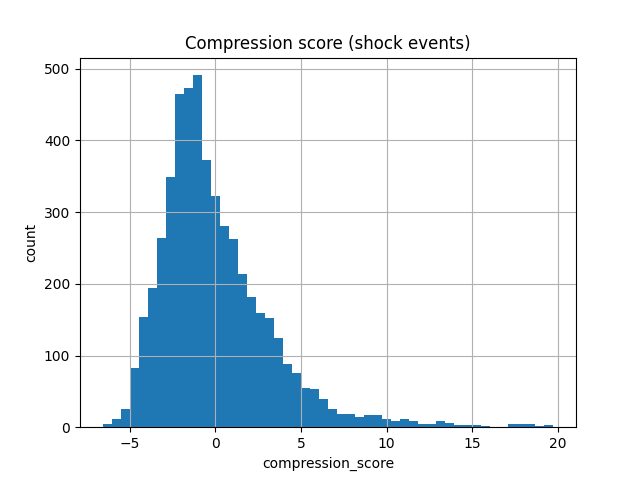

In [19]:
import matplotlib.pyplot as plt

ax = event_features_df["compression_score"].hist(bins=50)
ax.set_title("Compression score (shock events)")
ax.set_xlabel("compression_score")
ax.set_ylabel("count")
plt.show()


## Non-Shock histogramming

In [20]:
rng = np.random.default_rng(42)

In [21]:
non_events = hf.sample_non_event_timestamps(dfs, events, rng)
len(non_events), non_events.head()


(5412,
       symbol            event_ts
 0  1INCHUSDT 2025-05-03 15:10:00
 1  1INCHUSDT 2025-03-28 20:20:00
 2  1INCHUSDT 2025-08-04 18:50:00
 3  1INCHUSDT 2025-02-23 22:55:00
 4  1INCHUSDT 2025-09-23 23:15:00)

In [22]:
rows = []
for _, row in non_events.iterrows():
    sym = row["symbol"]
    ts  = row["event_ts"]
    df = dfs[sym]

    feats = hf.extract_pre_shock_features(df, ts)
    if feats is None:
        continue

    feats["symbol"] = sym
    feats["event_ts"] = ts
    rows.append(feats)

non_event_features_df = pd.DataFrame(rows).set_index(["symbol", "event_ts"])
non_event_features_df.describe()


,vol_ratio,atr_ratio,entropy,volume_ratio,failed_breakouts
count,5412.000000,5412.000000,5412.000000,5412.000000,5412.000000
mean,0.952548,0.982360,0.080305,0.979560,5.094605
std,0.253436,0.278093,0.059732,0.479422,2.386417
min,0.247596,0.273049,0.000000,0.143399,0.000000
25%,0.775361,0.796762,0.032553,0.652738,3.000000
50%,0.932821,0.956083,0.069624,0.892011,5.000000
75%,1.106411,1.124451,0.114988,1.203156,6.000000
max,2.444363,4.863172,0.379538,5.591181,20.000000


In [23]:
z_cols = ["vol_ratio", "atr_ratio", "entropy", "volume_ratio"]

mu = event_features_df[z_cols].mean()
sd = event_features_df[z_cols].std()

for col in z_cols:
    non_event_features_df[f"z_{col}"] = (non_event_features_df[col] - mu[col]) / sd[col]

non_event_features_df["compression_score"] = non_event_features_df[
    ["z_vol_ratio", "z_atr_ratio", "z_entropy", "z_volume_ratio"]
].sum(axis=1)


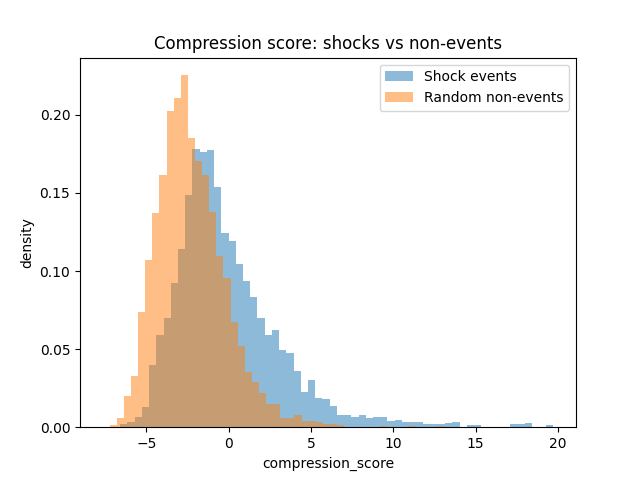

In [24]:
plt.figure()
plt.hist(event_features_df["compression_score"], bins=60, alpha=0.5, density=True, label="Shock events")
plt.hist(non_event_features_df["compression_score"], bins=60, alpha=0.5, density=True, label="Random non-events")
plt.legend()
plt.title("Compression score: shocks vs non-events")
plt.xlabel("compression_score")
plt.ylabel("density")
plt.show()


# Compression Filter (Find pre-shock entries)

In [108]:
importlib.reload(hf)

<module 'helper_functions' from '/home/ata/binbot/helper_functions.py'>

In [109]:
plt.close()

In [110]:
COMPRESSION_THRESH = -2.6
RANGE_BARS = 24   # last 2 hours

eligible_events = event_features_df[
    event_features_df["compression_score"] < COMPRESSION_THRESH
]
len(eligible_events), len(eligible_events) / len(event_features_df)

entries = []

for (sym, ts), row in eligible_events.iterrows():
    df = dfs[sym]
    res = hf.find_pre_shock_entry(df, ts)
    # res = hf.find_pre_shock_entry_v2(df, ts, BODY_ATR_MULT=0.7)
    # res = hf.find_pre_shock_entry_delayed(
    #     df, ts,
    #     CONFIRM_BARS=2,
    #     BREAK_ATR_BUFFER=0.20,
    #     USE_RVOL=True,
    #     RVOL_MIN=1.2
    # )

    if res is None:
        continue

    res["symbol"] = sym
    res["event_ts"] = ts
    res["compression_score"] = row["compression_score"]
    entries.append(res)

# expected_cols = ["symbol","event_ts","entry_ts","direction","entry_price","compression_score"]
# entries_df = pd.DataFrame(entries, columns=expected_cols)

# entries_df = entries_df.merge(
#     events[["symbol","event_ts","shock_direction","impulse_signed","impulse"]],
#     on=["symbol","event_ts"],
#     how="left"
# )

entries_df = pd.DataFrame(entries)
entries_df = entries_df.merge(
    events[["symbol","event_ts","shock_direction","impulse_signed","impulse"]],
    on=["symbol","event_ts"],
    how="left"
)

entries_df.describe()


,entry_ts,entry_price,event_ts,compression_score,impulse_signed,impulse
count,148,148.000000,148,148.000000,148.000000,148.000000
mean,2025-04-29 11:37:50.270270208,14.267806,2025-04-29 14:13:16.621621760,-3.587760,0.013519,0.051410
min,2025-02-04 02:10:00,0.000009,2025-02-04 05:10:00,-5.919288,-0.071816,0.040040
25%,2025-02-27 23:47:30,0.196048,2025-02-28 02:15:00,-4.106964,-0.044132,0.042875
50%,2025-04-12 11:45:00,1.022500,2025-04-12 14:02:30,-3.500588,0.041928,0.045624
75%,2025-06-23 14:00:00,6.398750,2025-06-23 16:30:00,-2.969478,0.049499,0.053622
max,2025-09-27 09:00:00,345.800000,2025-09-27 12:00:00,-2.610547,0.220015,0.220015
std,NaN,44.836809,NaN,0.737499,0.052995,0.018207


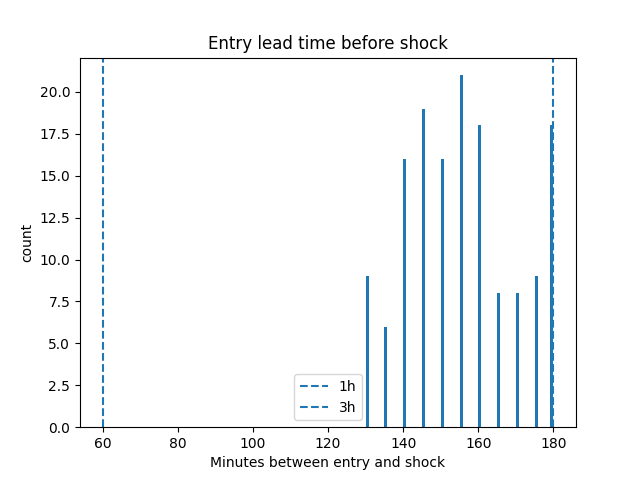

In [111]:
dt_minutes = (
    entries_df["event_ts"] - entries_df["entry_ts"]
).dt.total_seconds() / 60

plt.figure()
plt.hist(dt_minutes, bins=60)
plt.axvline(60, linestyle="--", label="1h")
plt.axvline(180, linestyle="--", label="3h")
plt.xlabel("Minutes between entry and shock")
plt.ylabel("count")
plt.title("Entry lead time before shock")
plt.legend()
plt.show()


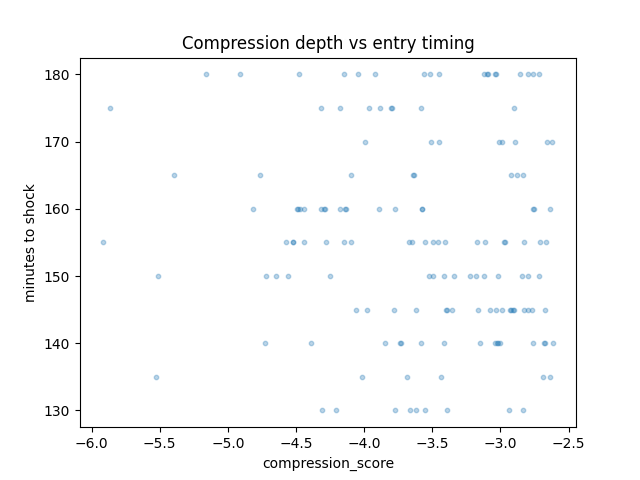

In [112]:
plt.figure()
plt.scatter(
    entries_df["compression_score"],
    dt_minutes,
    alpha=0.3,
    s=10
)
plt.xlabel("compression_score")
plt.ylabel("minutes to shock")
plt.title("Compression depth vs entry timing")
plt.show()


In [113]:
entries_df["direction"].value_counts(normalize=True)


direction
short    0.506757
long     0.493243
Name: proportion, dtype: float64

## Direction alignment filtering

In [114]:
entries_df["shock_direction"] = entries_df.apply(
    hf.compute_shock_direction,
    axis=1,
    args=(dfs,)
)

entries_df["shock_direction"].value_counts()


shock_direction
long     91
short    57
Name: count, dtype: int64

In [115]:
aligned_entries = entries_df[
    entries_df["direction"] == entries_df["shock_direction"]
]
aligned_entries["direction"].value_counts(normalize=True)


direction
long     0.807692
short    0.192308
Name: proportion, dtype: float64

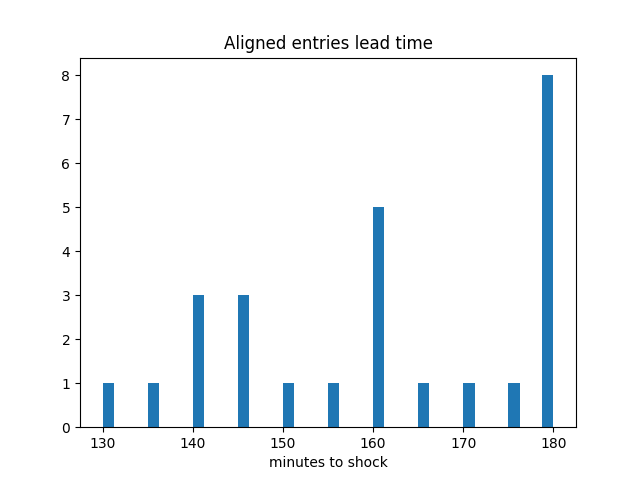

In [116]:
dt_aligned = (
    aligned_entries["event_ts"] - aligned_entries["entry_ts"]
).dt.total_seconds() / 60

plt.figure()
plt.hist(dt_aligned, bins=40)
plt.xlabel("minutes to shock")
plt.title("Aligned entries lead time")
plt.show()


In [117]:
BAR_MINUTES = 5
FEE = 0.001  # 0.1% spot fee (round-trip will be 2x if you want later)

rows = []

for _, r in aligned_entries.iterrows():
    sym = r["symbol"]
    df  = dfs[sym]

    entry_ts = r["entry_ts"]
    event_ts = r["event_ts"]
    exit_ts  = event_ts + pd.Timedelta(minutes=BAR_MINUTES)

    # safety checks
    if entry_ts not in df.index:
        continue
    if exit_ts not in df.index:
        continue

    entry_px = df.loc[entry_ts, "close"]
    exit_px  = df.loc[exit_ts, "close"]

    if r["direction"] == "long":
        ret = (exit_px - entry_px) / entry_px
    else:  # short
        ret = (entry_px - exit_px) / entry_px

    ret_net = ret - 2*FEE

    rows.append({
        "symbol": sym,
        "direction": r["direction"],
        "entry_ts": entry_ts,
        "event_ts": event_ts,              # ✅ keep it
        "exit_ts": exit_ts,
        "entry_px": entry_px,
        "exit_px": exit_px,
        "ret": ret,
        "ret_net": ret_net,
        "compression_score": r["compression_score"],
    })


trades = pd.DataFrame(rows)
len(trades)


26

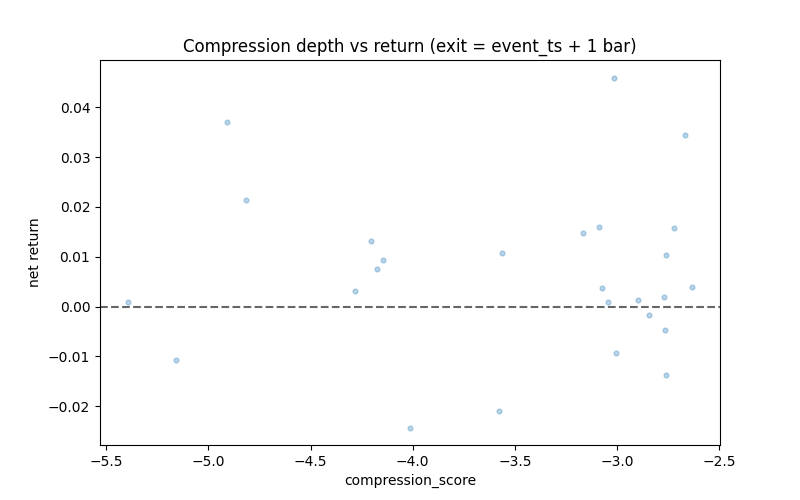

In [118]:
plt.figure(figsize=(8,5))
plt.scatter(
    trades["compression_score"],
    trades["ret_net"],
    alpha=0.3,
    s=12
)
plt.axhline(0, linestyle="--", color="k", alpha=0.6)
plt.xlabel("compression_score")
plt.ylabel("net return")
plt.title("Compression depth vs return (exit = event_ts + 1 bar)")
plt.show()


In [119]:
trades["comp_bucket"] = pd.qcut(
    trades["compression_score"],
    q=4,
    labels=["Q1 (deep)","Q2","Q3","Q4 (shallow)"]
)

bucket_stats = trades.groupby("comp_bucket")["ret_net"].agg(
    count="count",
    mean="mean",
    median="median",
    win_rate=lambda s: (s > 0).mean()
)

bucket_stats


/tmp/ipykernel_889/2940587472.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bucket_stats = trades.groupby("comp_bucket")["ret_net"].agg(


,count,mean,median,win_rate
comp_bucket,,,,
Q1 (deep),7,0.010369,0.007459,0.857143
Q2,6,0.000930,0.010062,0.666667
Q3,6,0.006856,0.001115,0.666667
Q4 (shallow),7,0.006846,0.003959,0.714286


# From this point onwards, we only consider long trades

In [120]:
long_trades = trades[trades["direction"] == "long"].copy()

long_trades["comp_bucket"] = pd.qcut(
    long_trades["compression_score"],
    q=4,
    labels=["Q1 (deep)","Q2","Q3","Q4 (shallow)"]
)
long_trades["comp_bucket"] = long_trades["comp_bucket"].astype("string")

long_bucket_stats = long_trades.groupby("comp_bucket")["ret_net"].agg(
    count="count",
    mean="mean",
    median="median",
    win_rate=lambda s: (s > 0).mean()
)


long_bucket_stats


,count,mean,median,win_rate
comp_bucket,,,,
Q1 (deep),6,0.010854,0.008193,0.833333
Q2,5,-0.002099,0.009412,0.600000
Q3,5,0.004097,0.001257,0.800000
Q4 (shallow),5,0.003643,0.003959,0.800000


In [121]:
long_trades = trades[trades["direction"] == "long"].copy()
len(long_trades), long_trades["symbol"].nunique()


(21, 18)

In [122]:
H1 = 24   # 2h
H2 = 72   # 6h
BAR_MIN = 5

In [123]:

rows = []
for _, r in long_trades.iterrows():
    sym = r["symbol"]
    res1 = hf.post_shock_stats_for_trade(sym, r["entry_ts"], r["event_ts"], r["direction"], dfs, H1)
    res2 = hf.post_shock_stats_for_trade(sym, r["entry_ts"], r["event_ts"], r["direction"], dfs, H2)
    if res1 is None or res2 is None:
        continue
    mfe1, mae1, ttp1, ret1 = res1
    mfe2, mae2, ttp2, ret2 = res2

    rows.append({
        "symbol": sym,
        "entry_ts": r["entry_ts"],
        "event_ts": r["event_ts"],
        "compression_score": r["compression_score"],
        "mfe_2h": mfe1, "mae_2h": mae1, "ttp_2h": ttp1, "ret_2h": ret1,
        "mfe_6h": mfe2, "mae_6h": mae2, "ttp_6h": ttp2, "ret_6h": ret2,
        "ret_net_v1": r["ret_net"],  # your current time-exit result
    })

post = pd.DataFrame(rows)
post.describe()


,entry_ts,event_ts,compression_score,mfe_2h,mae_2h,ttp_2h,ret_2h,mfe_6h,mae_6h,ttp_6h,ret_6h,ret_net_v1
count,21,21,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000,21.000000
mean,2025-04-17 10:02:08.571428352,2025-04-17 12:44:17.142856960,-3.610763,0.024908,-0.015986,12.285714,0.001091,0.069034,-0.020715,48.428571,0.046668,0.004444
min,2025-02-09 20:25:00,2025-02-09 22:40:00,-5.393167,-0.006231,-0.074136,0.000000,-0.063184,0.006515,-0.074136,0.000000,-0.050489,-0.024277
25%,2025-03-04 11:35:00,2025-03-04 14:35:00,-4.203808,0.015859,-0.024430,3.000000,-0.015309,0.035021,-0.034035,40.000000,0.016568,0.000963
50%,2025-03-04 14:35:00,2025-03-04 17:35:00,-3.165618,0.025797,-0.012592,14.000000,0.007767,0.054542,-0.015691,59.000000,0.030349,0.003769
75%,2025-06-23 14:45:00,2025-06-23 17:25:00,-2.842860,0.035021,0.000000,20.000000,0.019194,0.105852,-0.004530,65.000000,0.086919,0.013236
max,2025-08-26 09:50:00,2025-08-26 12:35:00,-2.633747,0.050787,0.010665,24.000000,0.039587,0.166993,0.010665,72.000000,0.155213,0.036998
std,NaN,NaN,0.896297,0.014356,0.020583,8.701396,0.026548,0.048163,0.021987,23.844436,0.050748,0.014143


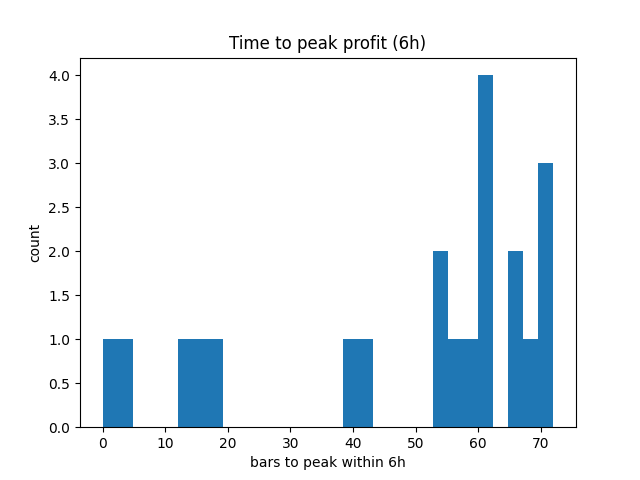

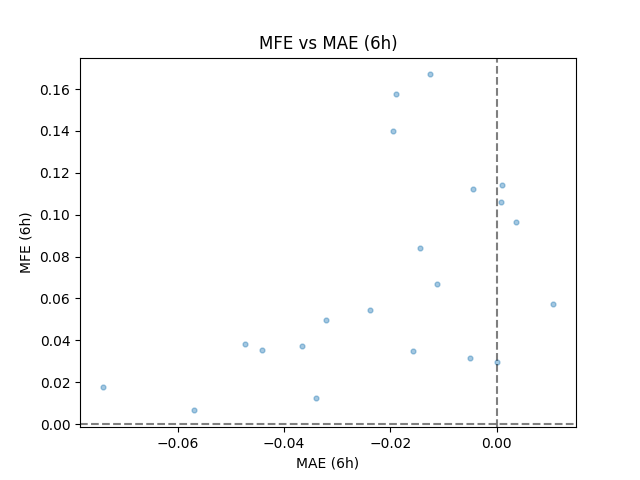

In [124]:
plt.figure()
plt.hist(post["ttp_6h"], bins=30)
plt.xlabel("bars to peak within 6h")
plt.ylabel("count")
plt.title("Time to peak profit (6h)")
plt.show()

plt.figure()
plt.scatter(post["mae_6h"], post["mfe_6h"], alpha=0.4, s=12)
plt.axhline(0, linestyle="--", color="k", alpha=0.5)
plt.axvline(0, linestyle="--", color="k", alpha=0.5)
plt.xlabel("MAE (6h)")
plt.ylabel("MFE (6h)")
plt.title("MFE vs MAE (6h)")
plt.show()


## Simulate Long Exits

In [125]:
results = []

for _, r in long_trades.iterrows():
    sym = r["symbol"]
    df  = dfs[sym]

    out = hf.simulate_long_exit_impulse(
        df=df,
        entry_ts=r["entry_ts"],
        event_ts=r["event_ts"],
        entry_px=r["entry_px"],
        H_MAX=72
    )
    if out is None:
        continue

    results.append({
        "symbol": sym,
        "entry_ts": r["entry_ts"],
        "event_ts": r["event_ts"],
        "entry_px": r["entry_px"],
        "compression_score": r["compression_score"],
        "comp_bucket": r.get("comp_bucket", np.nan),
        **out
    })

trades_v5 = pd.DataFrame(results)
trades_v5.shape


(21, 21)

In [126]:
hf.summarize(trades_v5)

trades_v5.groupby("exit_reason")["ret_net"].agg(
    count="count",
    mean="mean",
    median="median",
    win_rate=lambda s: (s > 0).mean()
).sort_values("count", ascending=False)


,count,mean,median,win_rate
exit_reason,,,,
IMPULSE_STALL,21,0.012029,0.013491,0.761905


In [127]:
base = trades[trades["direction"]=="long"].copy()

m = base.merge(
    trades_v5,
    on=["symbol","entry_ts","event_ts"],
    how="inner",
    suffixes=("_base", "_v5")
)

hf.summarize(m.rename(columns={"ret_net_base":"ret_net"}))
hf.summarize(m.rename(columns={"ret_net_v5":"ret_net"}))

(m["ret_net_v5"] - m["ret_net_base"]).describe()


count    21.000000
mean      0.007584
std       0.021904
min      -0.023589
25%      -0.003115
50%      -0.000858
75%       0.017284
max       0.066219
dtype: float64

In [128]:
trades_v5_ref = trades_v5.copy()

## Baseline Comparison

In [129]:
trades_base = trades[trades["direction"]=="long"].copy()   # your baseline long trades
trades_v5_ref = trades_v5.copy()                           # fee-correct v5.1

cmp = hf.compare_vs_baseline(trades_base, trades_v5_ref, ret_col="ret_net")
summary = hf.summarize_cmp(cmp, ret_col="ret_net")

summary["overall"]
summary["by_bucket"]
summary["by_reason"]


,count,mean,median,win_rate
exit_reason,,,,
IMPULSE_STALL,21,0.012029,0.013491,0.761905


In [130]:
print(trades_v5_ref["exit_reason"].value_counts())
print(hf.summarize_cmp(hf.compare_vs_baseline(trades_base, trades_v5_ref, ret_col="ret_net"))["overall"])
print(hf.summarize_cmp(hf.compare_vs_baseline(trades_base, trades_v5_ref, ret_col="ret_net"))["by_reason"])


exit_reason
IMPULSE_STALL    21
Name: count, dtype: int64
{'n': 21, 'mean_base': 0.00444436231617036, 'mean_v5': 0.01202856091600979, 'mean_delta': 0.007584198599839428, 'median_delta': -0.000858369098712581, 'winrate_base': 0.7619047619047619, 'winrate_v5': 0.7619047619047619, 'pct_improved': 0.47619047619047616}
               count      mean    median  win_rate
exit_reason                                       
IMPULSE_STALL     21  0.012029  0.013491  0.761905


In [131]:
coin_perf = (
    trades_v5_ref
    .groupby("symbol")
    .agg(
        n=("ret_net", "count"),
        mean_ret=("ret_net", "mean"),
        median_ret=("ret_net", "median"),
        win_rate=("ret_net", lambda x: (x > 0).mean()),
        total_ret=("ret_net", "sum"),
    )
    .sort_values("total_ret", ascending=False)
)

# Best contributor
best = coin_perf.index[0]

# Worst (with n >= 2)
worst = coin_perf.query("n >= 2").sort_values("total_ret").index[0]

# Middle (median total return)
mid = coin_perf.iloc[len(coin_perf)//2].name

best, mid, worst


('EIGENUSDT', 'VANAUSDT', 'AUCTIONUSDT')

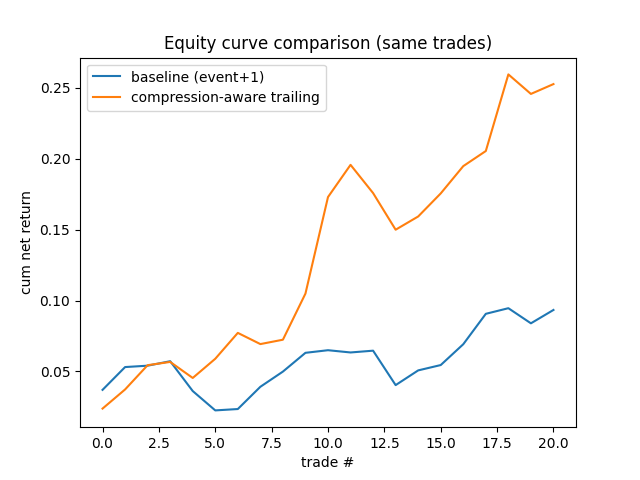

In [132]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(np.cumsum(m["ret_net_base"].values), label="baseline (event+1)")
plt.plot(np.cumsum(m["ret_net_v5"].values), label="compression-aware trailing")
plt.legend()
plt.title("Equity curve comparison (same trades)")
plt.xlabel("trade #")
plt.ylabel("cum net return")
plt.show()


In [137]:
importlib.reload(hf)

<module 'helper_functions' from '/home/ata/binbot/helper_functions.py'>

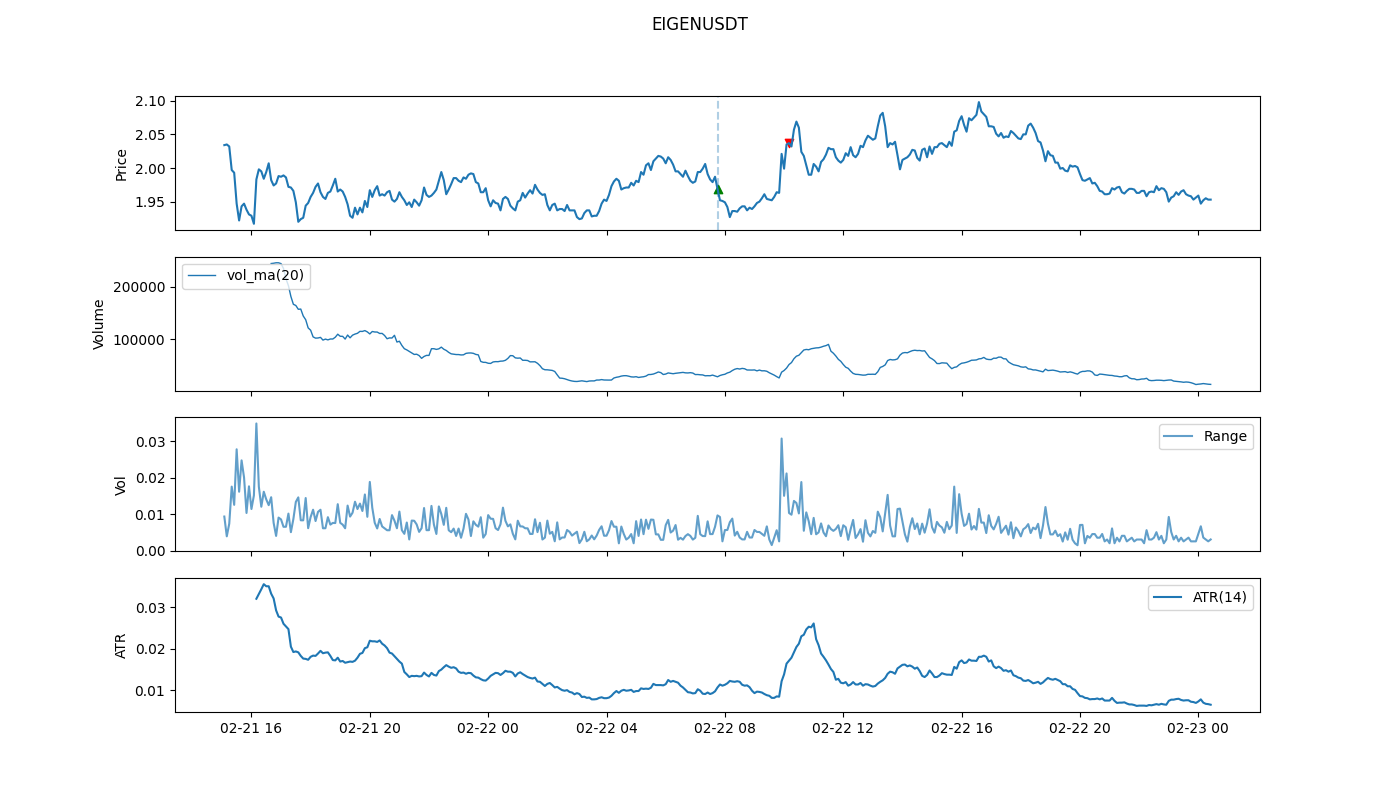

In [133]:
# pick a symbol you care about
sym = best

df = dfs[sym]
t = trades_v5_ref[trades_v5_ref["symbol"] == sym].iloc[0]

center_ts = t["entry_ts"]

hf.plot_context_v2(
    df,
    trades=trades_v5_ref[trades_v5_ref["symbol"] == sym],
    center_ts=center_ts,
    title=sym
)


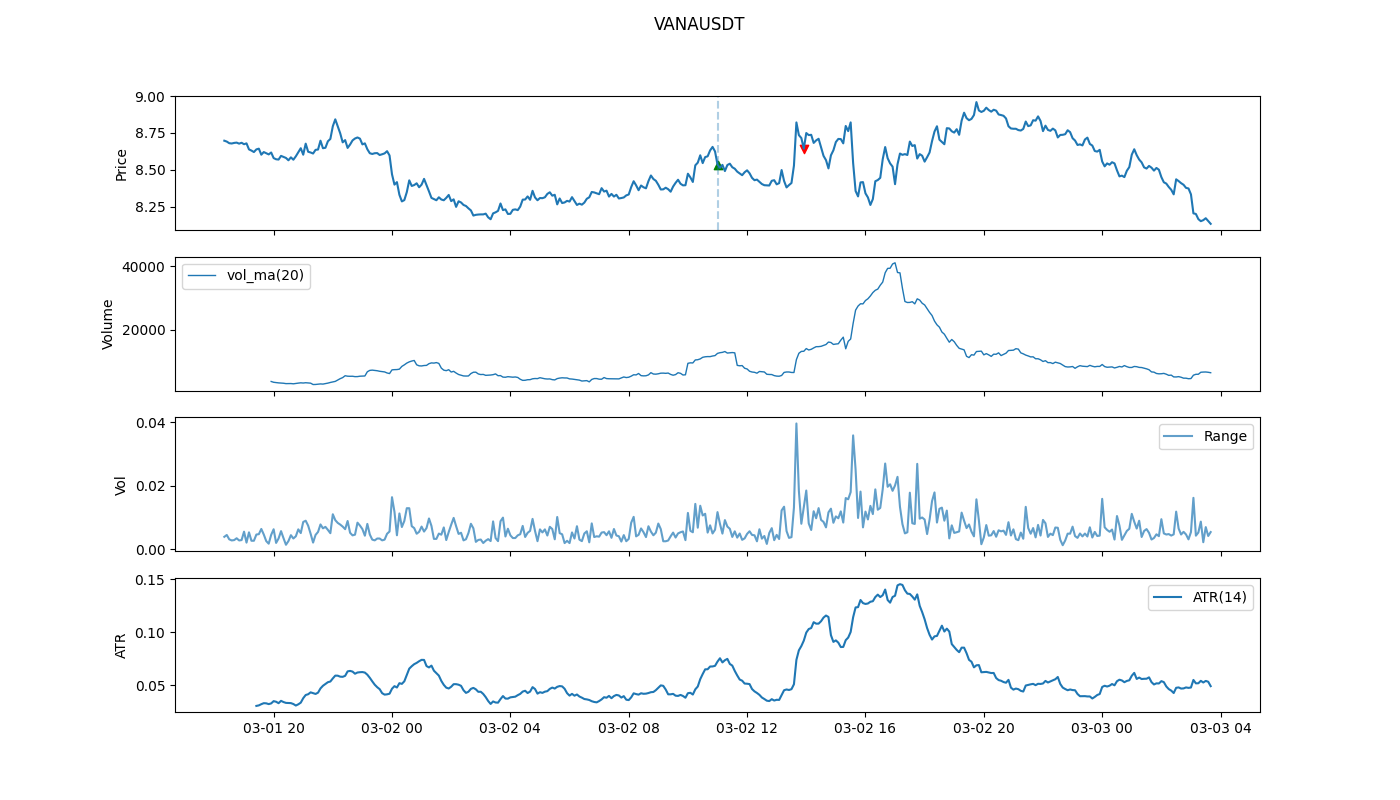

In [134]:
# pick a symbol you care about
sym = mid

df = dfs[sym]
t = trades_v5_ref[trades_v5_ref["symbol"] == sym].iloc[0]

center_ts = t["entry_ts"]

hf.plot_context_v2(
    df,
    trades=trades_v5_ref[trades_v5_ref["symbol"] == sym],
    center_ts=center_ts,
    title=sym
)


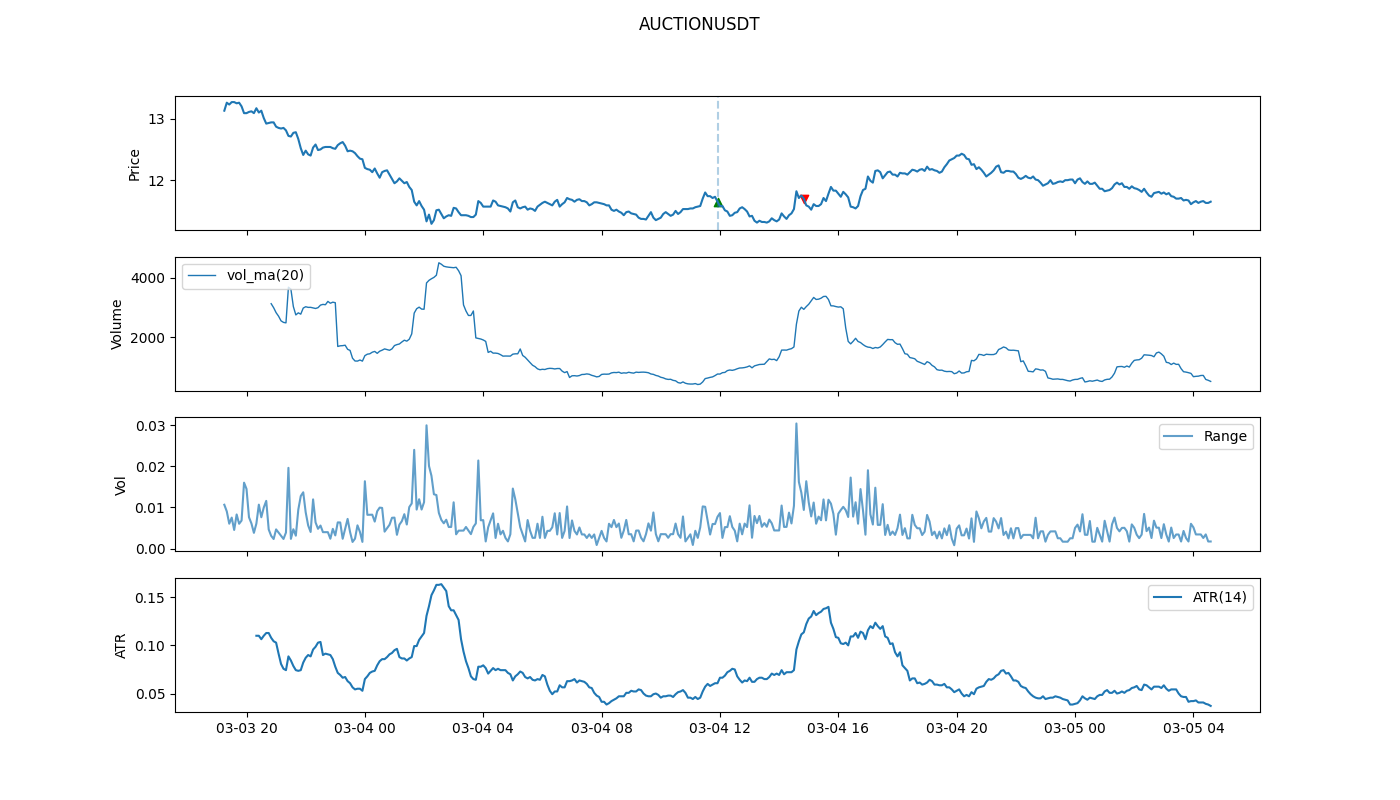

In [135]:
# pick a symbol you care about
sym = worst

df = dfs[sym]
t = trades_v5_ref[trades_v5_ref["symbol"] == sym].iloc[0]

center_ts = t["entry_ts"]

hf.plot_context_v2(
    df,
    trades=trades_v5_ref[trades_v5_ref["symbol"] == sym],
    center_ts=center_ts,
    title=sym
)
